Found 13 run(s) in output_poiseuille_experiment_alt/
Discrete cross-section factor S = 166675.0000 (continuum nY^3/6 = 166666.6667)

eta(0,0) from the xi0 = 0 run: 0.050000  (nominal 0.050000, +0.000%)

 xi0  wtB   iter        F            Q      eta       g    resid
 0.0  0.0 600000 4.00e-09 1.316732e-02 0.050000 +0.0000 2.69e-08
 1.0  0.0 600000 4.00e-09 1.262721e-02 0.052139 +0.1426 2.94e-06
 2.5  0.0 600000 4.00e-09 1.145346e-02 0.057482 +0.4988 6.86e-06
 5.0  0.0 600000 4.00e-09 1.071747e-02 0.061429 +0.7619 8.90e-06
10.0  0.0 600000 4.00e-09 1.039265e-02 0.063349 +0.8899 9.94e-06
15.0  0.0 600000 4.00e-09 1.029805e-02 0.063931 +0.9287 1.03e-05
20.0  0.0 600000 4.00e-09 1.025332e-02 0.064210 +0.9473 1.04e-05
 1.0  2.0 600000 4.00e-09 1.320436e-02 0.049860 -0.0094 6.60e-05
 2.5  2.0 600000 4.00e-09 1.339129e-02 0.049164 -0.0558 4.18e-04
 5.0  2.0 600000 4.00e-09 1.392302e-02 0.047286 -0.1809 1.68e-03
10.0  2.0 600000 4.00e-09 1.422059e-02 0.046297 -0.2469 4.44e-03
15.0  2.0 600000 

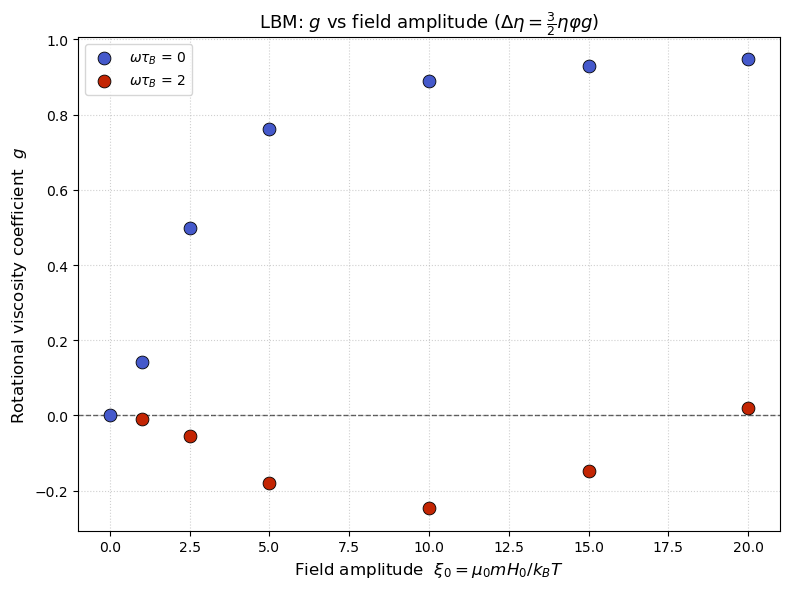

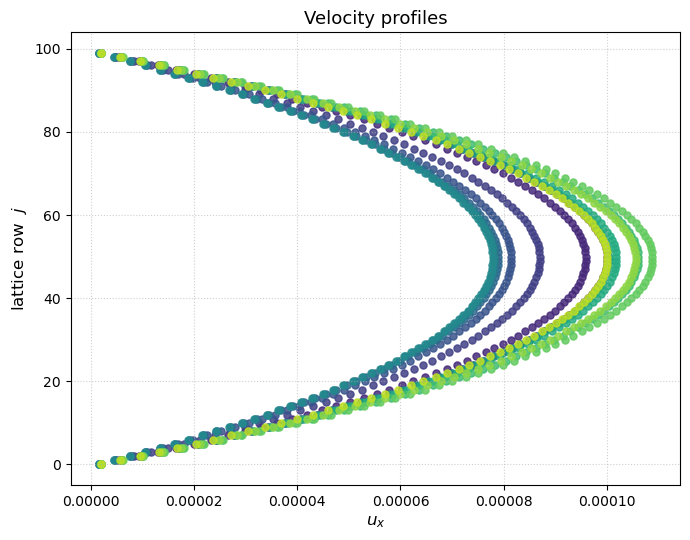

In [22]:
"""
Post-processing for phaseField_poiseuille.cpp.

The viscosity comes from the mass flow rate at a single driving force.  The
Poiseuille line passes through the origin exactly -- zero force gives zero
flow, with no offset to fit -- so one (F, Q) pair determines the slope:

    Q(F) = rho * S * F / (2 eta)        =>      eta = rho * S * F / (2 Q)

with  Q = sum_j rho_j ux_j  (mass flow per unit width) and

    S = sum_j (j + 1/2)(nY - 1/2 - j)

evaluated as the exact DISCRETE sum, not the continuum nY^3/6.  Using the
continuum value biases every eta by ~0.08%, which does not cancel in the
ratio below and gets amplified by 2/(3 phi_p) = 3.33 on its way into g.
With the discrete S a zero-field run returns eta_h exactly.

Then, from Bacri Eq. (10), Delta_eta = (3/2) eta phi_p g, so

    g = (2 / (3 phi_p)) * (eta - eta_0) / eta_0
"""

import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# 1. Configuration -- must match the C++ globals
# ----------------------------------------------------------------------
BASE_DIR = "output_poiseuille_experiment_alt"  # folder containing the run subfolders

nY    = 100       # channel height in lattice nodes
phi_p = 0.2      # PARTICLE volume fraction (the theory's phi)
eta_h = 0.05     # field-free dynamic viscosity

# Rows to drop at each wall when checking the profile shape.  My_safe()
# extrapolates linearly, exact for the continuum solution but not quite for
# the bounce-back node.  This affects the DIAGNOSTIC only, never eta.
NEDGE = 1

FOLDER_RE = re.compile(r"output_xi0_(-?[\d.]+)_wtB_(-?[\d.]+)")

# Discrete cross-section factor
_j = np.arange(nY)
S_DISCRETE = float(np.sum((_j + 0.5) * (nY - 0.5 - _j)))


# ----------------------------------------------------------------------
# 2. Load
# ----------------------------------------------------------------------
def latest_csv(folder):
    """Newest output_t_*.csv in a run folder, by iteration number."""
    files = glob.glob(os.path.join(folder, "output_t_*.csv"))
    if not files:
        return None, None

    def it_of(p):
        m = re.search(r"output_t_(\d+)\.csv$", p)
        return int(m.group(1)) if m else -1

    best = max(files, key=it_of)
    return best, it_of(best)


def read_run(csv_path):
    df = pd.read_csv(csv_path, skipinitialspace=True)
    prof = df.groupby("j").agg(ux=("ux", "mean"),
                               rho=("rho", "mean")).sort_index()
    y   = prof.index.to_numpy(dtype=float)
    ux  = prof["ux"].to_numpy()
    rho = prof["rho"].to_numpy()
    Q   = float(np.sum(rho * ux))
    F   = float(df["Fb_x"].mean())
    return F, Q, float(rho.mean()), y, ux


def parabola_residual(y, ux):
    """
    Relative RMS deviation from a parabola.  g is independent of Omega only
    at leading order in Omega*tau_B; outside that regime g becomes
    shear-dependent and the profile stops being parabolic.  This is the cheap
    way to notice.
    """
    yi = y[NEDGE:len(y) - NEDGE]
    ui = ux[NEDGE:len(ux) - NEDGE]
    basis = (yi + 0.5) * (nY - 0.5 - yi)
    amp = float(np.sum(basis * ui) / np.sum(basis * basis))
    resid = ui - amp * basis
    scale = np.max(np.abs(ui)) if np.max(np.abs(ui)) > 0 else 1.0
    return float(np.sqrt(np.mean(resid ** 2)) / scale)


# ----------------------------------------------------------------------
# 3. Build the results table
# ----------------------------------------------------------------------
if not os.path.isdir(BASE_DIR):
    raise SystemExit(f"No such directory: {BASE_DIR}")

rows = []
for name in sorted(os.listdir(BASE_DIR)):
    folder = os.path.join(BASE_DIR, name)
    if not os.path.isdir(folder):
        continue
    m = FOLDER_RE.match(name)
    if not m:
        continue
    xi0, wtB = float(m.group(1)), float(m.group(2))

    csv_path, it = latest_csv(folder)
    if csv_path is None:
        print(f"  skip {name}: no CSV")
        continue
    try:
        F, Q, rho, y, ux = read_run(csv_path)
    except Exception as e:
        print(f"  skip {name}: {e}")
        continue
    if not np.isfinite(Q) or abs(Q) < 1e-30 or abs(F) < 1e-30:
        print(f"  skip {name}: F={F:g}, Q={Q:g}")
        continue

    rows.append(dict(xi0=xi0, wtB=wtB, iter=it, F=F, Q=Q, rho=rho,
                     eta=rho * S_DISCRETE * F / (2.0 * Q),
                     resid=parabola_residual(y, ux),
                     umax=float(np.max(ux)), y=y, ux=ux))

if not rows:
    raise SystemExit(f"No usable runs found under {BASE_DIR}/")

res = pd.DataFrame(rows).sort_values(["wtB", "xi0"]).reset_index(drop=True)

print(f"Found {len(res)} run(s) in {BASE_DIR}/")
print(f"Discrete cross-section factor S = {S_DISCRETE:.4f} "
      f"(continuum nY^3/6 = {nY ** 3 / 6:.4f})\n")

# Zero-field reference.  At xi0 = 0 the C++ sets Ms = 0, so M = 0 and the flow
# is pure Poiseuille -- that run measures eta(0,0) directly, which is what
# Bacri normalise by.  Fall back to nominal eta_h if it wasn't run.
zero = res[np.isclose(res["xi0"], 0.0)]
if len(zero):
    eta0 = float(zero["eta"].mean())
    print(f"eta(0,0) from the xi0 = 0 run: {eta0:.6f}  "
          f"(nominal {eta_h:.6f}, {100 * (eta0 / eta_h - 1):+.3f}%)\n")
else:
    eta0 = eta_h
    print(f"No xi0 = 0 run found; using nominal eta_h = {eta_h:.6f}.\n"
          f"  Worth running one: it measures the LBM baseline directly, and\n"
          f"  any error there propagates into every g.\n")

res["g"] = (2.0 / (3.0 * phi_p)) * (res["eta"] - eta0) / eta0

with pd.option_context("display.width", 200, "display.max_columns", 20):
    print(res[["xi0", "wtB", "iter", "F", "Q", "eta", "g", "resid"]]
          .to_string(index=False,
                     formatters={"F": "{:.2e}".format, "Q": "{:.6e}".format,
                                 "eta": "{:.6f}".format, "g": "{:+.4f}".format,
                                 "resid": "{:.2e}".format}))

bad = res[res["resid"] > 1e-3]
if len(bad):
    print(f"\nWARNING: {len(bad)} case(s) deviate from a parabola by >0.1%, "
          f"so g may be shear-dependent there\n  (i.e. Omega*tau_B no longer "
          f"<< 1).  Lower Fb_x and re-check.")


# ----------------------------------------------------------------------
# 4. g vs xi0, one series per omega*tau_B   (Bacri Fig. 3 layout)
# ----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))
wtBs = sorted(res["wtB"].unique())
colors = plt.cm.turbo(np.linspace(0.1, 0.9, max(1, len(wtBs))))

for c, wtB in zip(colors, wtBs):
    sub = res[res.wtB == wtB].sort_values("xi0")
    ax.scatter(sub["xi0"], sub["g"], s=85, color=c, edgecolors="k",
               linewidths=0.6, zorder=3, label=rf"$\omega\tau_B$ = {wtB:g}")

ax.axhline(0, color="k", lw=1.0, ls="--", alpha=0.6)
ax.set_xlabel(r"Field amplitude  $\xi_0 = \mu_0 m H_0 / k_B T$", fontsize=12)
ax.set_ylabel(r"Rotational viscosity coefficient  $g$", fontsize=12)
ax.set_title(r"LBM: $g$ vs field amplitude "
             r"($\Delta\eta = \frac{3}{2}\eta\varphi g$)", fontsize=13)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(fontsize=10, loc="best")
fig.tight_layout()
plt.show()


# ----------------------------------------------------------------------
# 5. Velocity profiles -- confirm they are parabolic
# ----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 5.5))
pcolors = plt.cm.viridis(np.linspace(0.05, 0.9, max(1, len(res))))

for c, r in zip(pcolors, res.itertuples()):
    ax.scatter(r.ux, r.y, s=26, color=c, alpha=0.85,
               label=rf"$\xi_0$={r.xi0:g}, $\omega\tau_B$={r.wtB:g}")

ax.set_xlabel(r"$u_x$", fontsize=12)
ax.set_ylabel(r"lattice row  $j$", fontsize=12)
ax.set_title("Velocity profiles", fontsize=13)
ax.grid(True, linestyle=":", alpha=0.6)
if len(res) <= 12:
    ax.legend(fontsize=8, loc="best")
fig.tight_layout()
plt.show()

# Post Validation, Comparing with theoretical plots

Found 13 run(s) in output_poiseuille_experiment_alt/   [velocity column: ux]
S = 166675.0000  (continuum nY^3/6 = 166666.6667)
eta from DC of the last 40% of snapshots (25-33 per run)

eta(0,0) from the xi0 = 0 run: 0.05000110  (nominal 0.050000, +0.002%)

Integrating theory for omega*tau_B = 0, 2 ...

 xi0  wtB   iter        eta       g  g_mrsh g_bacri     dev ratio    swing  fit_res    resid
 0.0  0.0 600000 0.05000110 +0.0000 +0.0000 +0.0000 +0.0000   NaN 1.22e-04 0.00e+00 2.69e-08
 1.0  0.0 600000 0.05213932 +0.1425 +0.1426 +0.1426 -0.0001 0.999 7.03e-05 0.00e+00 2.94e-06
 2.5  0.0 600000 0.05748203 +0.4987 +0.4989 +0.4989 -0.0002 1.000 2.04e-05 0.00e+00 6.86e-06
 5.0  0.0 600000 0.06142936 +0.7619 +0.7621 +0.7621 -0.0002 1.000 1.07e-05 0.00e+00 8.90e-06
10.0  0.0 600000 0.06334931 +0.8899 +0.8901 +0.8901 -0.0002 1.000 8.91e-06 0.00e+00 9.94e-06
15.0  0.0 600000 0.06393121 +0.9287 +0.9289 +0.9289 -0.0003 1.000 8.59e-06 0.00e+00 1.03e-05
20.0  0.0 600000 0.06421011 +0.9472 +0.9475 +

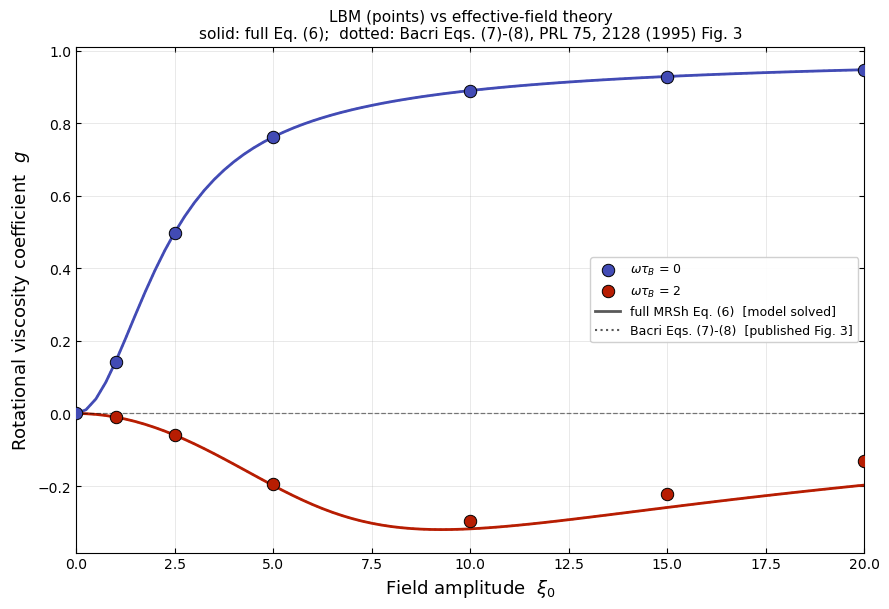

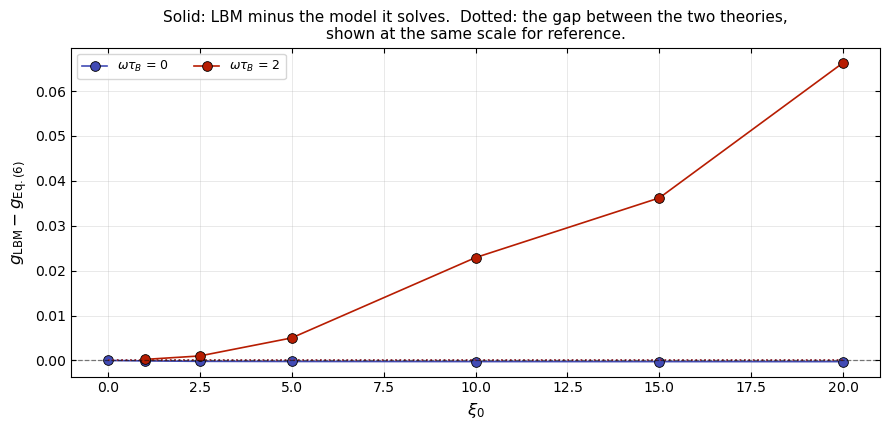

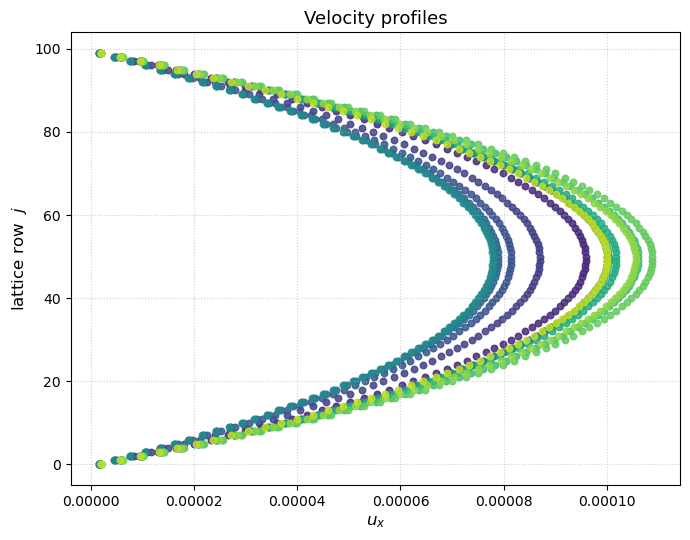

In [23]:
"""
LBM results for the rotational viscosity of a ferrofluid in an alternating
field, against BOTH relevant theory curves.

SIMULATION SIDE
    eta = rho * S * F / (2 Q),   Q = sum_j rho_j ux_j,      taken from the DC
    part of a harmonic fit over the converged tail, NOT from a single snapshot
    (see dc_from_run).  At wtB = 2, xi_0 = 20 that alone moves g from -0.064
    to -0.157.
    S   = sum_j (j + 1/2)(nY - 1/2 - j)      [exact discrete sum]
    g   = (2 / (3 phi_p)) (eta - eta_0) / eta_0     [from Bacri Eq. (10)]

THEORY SIDE -- two curves, because they are NOT the same thing:

  (a) FULL MRSh, Bacri Eq. (6), integrated as a vector ODE for xi_e.  This is
      the model compute_M actually solves, so it is the correct target for
      validating the solver:

          d(xi_e)/dt = Omega x xi_e
                     - (L_e/L_e')(1 - xi.n / xi_e) n / tau_B
                     + (1/2)(xi_e/L_e - 1)(xi - n (xi.n)) / tau_B

          M = phi Ms L(xi_e) n,   g = xi_0 <m_y cos(wt)> / (2 Omega tau_B)

  (b) Bacri Eqs. (7)-(8), the ZERO APPROXIMATION in Omega*tau_B -- the curve
      actually printed in their Fig. 3:

          d(xi_e)/dt = -L/L' + [L/(xi_e L')] xi_0 cos(wt)
          dY/dt      =  L(xi_e) - Y [1 - xi_0 cos(wt) B(xi_e)]
          g          =  (1/2) xi_0 <Y cos(wt)>

  Integrated correctly the two agree to 5 decimals -- (b) is the O(Omega tau_B)
  reduction of (a), and Omega tau_B ~ 1e-3 here.  Both are kept because they
  are separate code paths and agreeing is a useful check.
  At wtB = 0 both reduce to the closed form g = xi_0 L^2 / (xi_0 - L).

  The old curve was NOT this.  It used h_max = 0.02 tau_B, i.e. N = 200 steps
  per period at wtB = 2.  The stiffest rate in the ODE is the parallel
  relaxation L/(L' tau_B) -> xi_e^2/tau_B, so h*rate = 0.0157*400 = 6.3 at
  xi_0 = 20 -- past the RK4 stability limit of 2.785.  That inflated g by 6%
  at xi_0 = 1 and 15% at xi_0 = 20.  h is now capped by SAFE_FAC/xi_0^2.

Both are integrated over a WHOLE NUMBER OF FIELD PERIODS.  A window that is a
fixed number of tau_B leaves a partial period whose contribution does not
cancel; that alone shifts g by several per cent.
"""

import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# 1. Configuration -- must match the C++ globals
# ----------------------------------------------------------------------
BASE_DIR = "output_poiseuille_experiment_alt"

nY    = 100      # channel height in lattice nodes
phi_p = 0.2      # PARTICLE volume fraction (the theory's phi)
eta_h = 0.05     # field-free dynamic viscosity

NEDGE = 1        # wall rows dropped in the shape DIAGNOSTIC only
UX_COL = "ux"    # switch to "ux_avg" once the C++ writes a period average

# Under an alternating field the flow settles on a LIMIT CYCLE, not a fixed
# point: the torque M x H carries a 2*omega component that never dies out.  A
# single snapshot therefore samples one phase of that ripple.  eta is taken
# from the DC part of a harmonic fit over the converged tail instead.
TAU_B = 13000.0  # Brownian time in lattice steps (C++ global) -- 2w phase
TAIL  = 0.40     # fraction of snapshots (by iteration) treated as converged

# Theory integration.  h is capped by RK4 stability: the stiffest rate in
# Eq. (6) is the parallel relaxation L/(L' tau_B) -> xi_e^2/tau_B at large
# argument, so h * xi_0^2 must stay well under the RK4 limit of 2.785.
OM_TAUB    = 1e-3   # Omega*tau_B used for the theory.  g is independent of it.
SETTLE_PER = 8      # periods discarded
AVG_PER    = 6      # periods averaged (whole periods -- load-bearing)
H_TARGET   = 1e-3   # max RK4 step in tau_B
SAFE_FAC   = 0.5    # h * xi_0^2 cap; RK4 is stable to 2.785, this is the margin
XI_GRID    = np.linspace(0.0, 20.0, 81)

FOLDER_RE = re.compile(r"output_xi0_(-?[\d.]+)_wtB_(-?[\d.]+)")

_j = np.arange(nY)
S_DISCRETE = float(np.sum((_j + 0.5) * (nY - 0.5 - _j)))


# ======================================================================
# 2. Special functions
# ======================================================================
# L is ODD, L' is EVEN, B is ODD.  xi_e passes through zero every time the
# field reverses, so the signs are load-bearing.

def L_vec(x):
    """coth(x) - 1/x.  Series below 0.2 avoids the coth - 1/x cancellation;
    asymptote above 200 avoids sinh overflow."""
    x = np.asarray(x, float); a = np.abs(x)
    s = np.where(a < 1e-12, 1.0, a)
    ser = a * (1/3 + a**2 * (-1/45 + a**2 * (2/945 - a**2/4725)))
    sc = np.clip(s, None, 200.0)
    ex = np.where(a > 200.0, 1.0 - 1.0/s, 1.0/np.tanh(sc) - 1.0/s)
    return np.sign(x) * np.where(a < 0.2, ser, ex)


def dL_vec(x):
    """L'(x) = 1/x^2 - 1/sinh^2(x)."""
    a = np.abs(np.asarray(x, float))
    s = np.where(a < 1e-12, 1.0, a)
    ser = 1/3 + a**2 * (-1/15 + a**2 * (2/189 - a**2/675))
    sc = np.clip(s, None, 200.0)
    ex = np.where(a > 200.0, 1.0/s**2, 1.0/s**2 - 1.0/np.sinh(sc)**2)
    return np.where(a < 0.2, ser, ex)


def B_vec(x):
    """B(x) = 3/(2x) - 1/(2L(x))."""
    x = np.asarray(x, float); a = np.abs(x)
    s = np.where(a < 1e-12, 1.0, a)
    ser = -a/10.0 + a**3/350.0 - a**5/3500.0
    return np.sign(x) * np.where(a < 0.05, ser, 1.5/s - 0.5/L_vec(s))


def _static(xi0):
    l = L_vec(xi0); out = np.zeros_like(xi0); nz = xi0 > 1e-10
    out[nz] = xi0[nz] * l[nz]**2 / (xi0[nz] - l[nz])
    return out


# ======================================================================
# 3a. Theory (a): full MRSh Eq. (6) -- the model compute_M solves
# ======================================================================
def g_mrsh(xi0, wtB, Om=OM_TAUB, settle_per=SETTLE_PER,
           avg_per=AVG_PER, h_target=H_TARGET):
    xi0 = np.atleast_1d(np.asarray(xi0, float))
    if wtB < 1e-12:
        return _static(xi0)

    P = 2.0 * np.pi / wtB
    rate = max(1.0, float(np.max(xi0)**2))
    h = min(h_target, SAFE_FAC / rate, P / 400.0)
    N = int(np.ceil(P / h)); h = P / N            # exact whole-period tiling

    ax = xi0.copy(); ay = np.zeros_like(xi0)
    I = np.zeros_like(xi0); t = 0.0

    def f(t, ax, ay):
        xt = xi0 * np.cos(wtB * t)
        xe = np.hypot(ax, ay); s = np.where(xe < 1e-12, 1.0, xe)
        nx, ny = ax/s, ay/s
        Le, dLe = L_vec(s), dL_vec(s)
        xpar = nx * xt
        par = -(Le/dLe) * (1.0 - xpar/s)
        cp  = 0.5 * (s/Le - 1.0)
        return (-Om*ay + par*nx + cp*(xt - nx*xpar),
                 Om*ax + par*ny + cp*(    - ny*xpar))

    def my_cos(t, ax, ay):
        xe = np.hypot(ax, ay); s = np.where(xe < 1e-12, 1.0, xe)
        return L_vec(s) * ay/s * np.cos(wtB*t)

    for phase in (0, 1):
        for _ in range(N * (settle_per if phase == 0 else avg_per)):
            if phase:
                a0 = my_cos(t, ax, ay)
            k1 = f(t,     ax,             ay)
            k2 = f(t+h/2, ax+h/2*k1[0],   ay+h/2*k1[1])
            k3 = f(t+h/2, ax+h/2*k2[0],   ay+h/2*k2[1])
            k4 = f(t+h,   ax+h*k3[0],     ay+h*k3[1])
            ax = ax + h/6*(k1[0] + 2*k2[0] + 2*k3[0] + k4[0])
            ay = ay + h/6*(k1[1] + 2*k2[1] + 2*k3[1] + k4[1])
            t += h
            if phase:
                I = I + 0.5*h*(a0 + my_cos(t, ax, ay))

    return xi0 * I / (avg_per * P) / (2.0 * Om)


# ======================================================================
# 3b. Theory (b): Bacri Eqs. (7)-(8) -- the published Fig. 3 curve
# ======================================================================
def g_bacri(xi0, wtB, settle_per=SETTLE_PER, avg_per=AVG_PER,
            h_target=H_TARGET):
    xi0 = np.atleast_1d(np.asarray(xi0, float))
    if wtB < 1e-12:
        return _static(xi0)

    P = 2.0 * np.pi / wtB
    rate = max(1.0, float(np.max(xi0)**2))
    h = min(h_target, SAFE_FAC / rate, P / 400.0)
    N = int(np.ceil(P / h)); h = P / N

    xe = xi0.copy(); Y = np.zeros_like(xi0)
    I = np.zeros_like(xi0); t = 0.0

    def fx(t, xe):
        Lv, dLv = L_vec(xe), dL_vec(xe)
        s = np.where(np.abs(xe) < 1e-12, 1.0, xe)
        return -Lv/dLv + (Lv/(s*dLv)) * xi0 * np.cos(wtB*t)

    def fy(t, xe, Y):
        return L_vec(xe) - Y*(1.0 - xi0*np.cos(wtB*t)*B_vec(xe))

    for phase in (0, 1):
        for _ in range(N * (settle_per if phase == 0 else avg_per)):
            if phase:
                a0 = Y * np.cos(wtB*t)
            k1x = fx(t, xe);                       k1y = fy(t, xe, Y)
            k2x = fx(t+h/2, xe+h/2*k1x)
            k2y = fy(t+h/2, xe+h/2*k1x, Y+h/2*k1y)
            k3x = fx(t+h/2, xe+h/2*k2x)
            k3y = fy(t+h/2, xe+h/2*k2x, Y+h/2*k2y)
            k4x = fx(t+h,   xe+h*k3x)
            k4y = fy(t+h,   xe+h*k3x, Y+h*k3y)
            xe = xe + h/6*(k1x + 2*k2x + 2*k3x + k4x)
            Y  = Y  + h/6*(k1y + 2*k2y + 2*k3y + k4y)
            t += h
            if phase:
                I = I + 0.5*h*(a0 + Y*np.cos(wtB*t))

    return 0.5 * xi0 * I / (avg_per * P)


# ======================================================================
# 4. Simulation
# ======================================================================
def all_csvs(folder):
    """Every output_t_*.csv in a run folder, sorted by iteration."""
    out = []
    for p in glob.glob(os.path.join(folder, "output_t_*.csv")):
        m = re.search(r"output_t_(\d+)\.csv$", p)
        if m:
            out.append((int(m.group(1)), p))
    return sorted(out)


def read_run(csv_path, ux_col=UX_COL):
    df = pd.read_csv(csv_path, skipinitialspace=True)
    col = ux_col if ux_col in df.columns else "ux"
    prof = df.groupby("j").agg(ux=(col, "mean"),
                               rho=("rho", "mean")).sort_index()
    y   = prof.index.to_numpy(dtype=float)
    ux  = prof["ux"].to_numpy()
    rho = prof["rho"].to_numpy()
    return (float(df["Fb_x"].mean()), float(np.sum(rho*ux)),
            float(rho.mean()), y, ux, col)


def dc_from_run(folder, wtB):
    """eta from the DC part of the converged tail.

    For wtB > 0 the tail is fitted with
        eta(t) = A + B cos(th) + C sin(th) + D cos(2 th) + E sin(2 th),
        th = 2 pi * iter / P2w,   P2w = pi * TAU_B / wtB     [the 2w period]
    and A is returned.  Snapshot spacing rarely divides P2w, so a plain tail
    MEAN does not cancel the ripple; the fit needs no commensurate sampling.
    For wtB = 0 the tail mean is used.

    Returns (eta_dc, swing, fit_res, F, Q, rho, y, ux, iter_last, n_tail, col).
    """
    recs = all_csvs(folder)
    if not recs:
        return None
    it_all = np.array([r[0] for r in recs], float)
    cut = it_all.min() + (1.0 - TAIL) * (it_all.max() - it_all.min())
    keep = [(i, p) for (i, p) in recs if i >= cut]
    if len(keep) < 2:
        keep = recs[-2:] if len(recs) >= 2 else recs

    it, eta, col = [], [], None
    for i, p in keep:
        F, Q, rho, y, ux, col = read_run(p)
        if not np.isfinite(Q) or abs(Q) < 1e-30 or abs(F) < 1e-30:
            continue
        it.append(float(i))
        eta.append(rho * S_DISCRETE * F / (2.0 * Q))
    if not it:
        return None
    it = np.asarray(it); eta = np.asarray(eta)

    if wtB > 1e-12 and len(eta) >= 6:
        P2w = np.pi * TAU_B / wtB
        th = 2.0 * np.pi * it / P2w
        M = np.column_stack([np.ones_like(th), np.cos(th), np.sin(th),
                             np.cos(2*th), np.sin(2*th)])
        coef, *_ = np.linalg.lstsq(M, eta, rcond=None)
        eta_dc = float(coef[0])
        fit_res = float(np.sqrt(np.mean((eta - M @ coef)**2)) /
                        max(abs(eta_dc), 1e-300))
    else:
        eta_dc, fit_res = float(eta.mean()), 0.0

    swing = float(eta.max() - eta.min()) / max(abs(eta_dc), 1e-300)
    F, Q, rho, y, ux, col = read_run(keep[-1][1])
    return (eta_dc, swing, fit_res, F, Q, rho, y, ux,
            int(keep[-1][0]), len(it), col)


def parabola_residual(y, ux):
    yi = y[NEDGE:len(y)-NEDGE]
    ui = ux[NEDGE:len(ux)-NEDGE]
    basis = (yi + 0.5) * (nY - 0.5 - yi)
    amp = float(np.sum(basis*ui) / np.sum(basis*basis))
    scale = np.max(np.abs(ui)) if np.max(np.abs(ui)) > 0 else 1.0
    return float(np.sqrt(np.mean((ui - amp*basis)**2)) / scale)


if not os.path.isdir(BASE_DIR):
    raise SystemExit(f"No such directory: {BASE_DIR}")

rows, used_col = [], None
for name in sorted(os.listdir(BASE_DIR)):
    folder = os.path.join(BASE_DIR, name)
    m = FOLDER_RE.match(name)
    if not (os.path.isdir(folder) and m):
        continue
    xi0, wtB = float(m.group(1)), float(m.group(2))
    try:
        got = dc_from_run(folder, wtB)
    except Exception as e:
        print(f"  skip {name}: {e}");  continue
    if got is None:
        print(f"  skip {name}: no usable CSV");  continue
    eta_dc, swing, fit_res, F, Q, rho, y, ux, it, ntail, col = got
    used_col = col
    if len(y) != nY:
        print(f"  skip {name}: nY={len(y)} != {nY}");  continue
    rows.append(dict(xi0=xi0, wtB=wtB, iter=it, ntail=ntail, F=F, Q=Q, rho=rho,
                     eta=eta_dc, swing=swing, fit_res=fit_res,
                     resid=parabola_residual(y, ux), y=y, ux=ux))

if not rows:
    raise SystemExit(f"No usable runs found under {BASE_DIR}/")

res = pd.DataFrame(rows).sort_values(["wtB", "xi0"]).reset_index(drop=True)
print(f"Found {len(res)} run(s) in {BASE_DIR}/   [velocity column: {used_col}]")
print(f"S = {S_DISCRETE:.4f}  (continuum nY^3/6 = {nY**3/6:.4f})")
print(f"eta from DC of the last {TAIL:.0%} of snapshots "
      f"({res.ntail.min()}-{res.ntail.max()} per run)\n")

zero = res[np.isclose(res["xi0"], 0.0)]
if len(zero):
    eta0 = float(zero["eta"].mean())
    print(f"eta(0,0) from the xi0 = 0 run: {eta0:.8f}  "
          f"(nominal {eta_h:.6f}, {100*(eta0/eta_h - 1):+.3f}%)")
    if abs(eta0/eta_h - 1) > 0.02:
        print("  WARNING: eta_0 is >2% off nominal -- the zero-field run is "
              "probably not converged; everything downstream inherits it.")
    print()
else:
    eta0 = eta_h
    print(f"No xi0 = 0 run; using nominal eta_h = {eta_h:.6f}.\n")

res["g"] = (2.0 / (3.0*phi_p)) * (res["eta"] - eta0) / eta0


# ======================================================================
# 5. Theory curves + comparison
# ======================================================================
wtBs = sorted(res["wtB"].unique())
print(f"Integrating theory for omega*tau_B = "
      f"{', '.join(f'{w:g}' for w in wtBs)} ...")
# Evaluate each theory ONCE per frequency, on the grid union the data points.
# Re-integrating per data point costs one full ODE solve each and dominates
# the runtime for no gain.
curves_mrsh, curves_bacri = {}, {}
gm_at, gb_at = {}, {}
for w in wtBs:
    pts = np.unique(np.concatenate([XI_GRID,
                                    res.loc[res.wtB == w, "xi0"].to_numpy()]))
    gm, gb = g_mrsh(pts, w), g_bacri(pts, w)
    keep = np.isin(pts, XI_GRID)
    curves_mrsh[w], curves_bacri[w] = gm[keep], gb[keep]
    gm_at[w] = dict(zip(pts, gm))
    gb_at[w] = dict(zip(pts, gb))

res["g_mrsh"]  = [gm_at[w][x] for x, w in zip(res.xi0, res.wtB)]
res["g_bacri"] = [gb_at[w][x] for x, w in zip(res.xi0, res.wtB)]
res["dev"]     = res["g"] - res["g_mrsh"]              # vs the model solved
res["ratio"]   = np.where(np.abs(res.g_mrsh) > 1e-12,
                          res.g / res.g_mrsh, np.nan)

print()
with pd.option_context("display.width", 220, "display.max_columns", 20):
    print(res[["xi0", "wtB", "iter", "eta", "g", "g_mrsh", "g_bacri",
               "dev", "ratio", "swing", "fit_res", "resid"]]
          .to_string(index=False,
                     formatters={"eta": "{:.8f}".format,
                                 "g": "{:+.4f}".format,
                                 "g_mrsh": "{:+.4f}".format,
                                 "g_bacri": "{:+.4f}".format,
                                 "dev": "{:+.4f}".format,
                                 "ratio": "{:.3f}".format,
                                 "swing": "{:.2e}".format,
                                 "fit_res": "{:.2e}".format,
                                 "resid": "{:.2e}".format}))

print(f"\nvs FULL MRSh Eq.(6) -- the model compute_M solves:")
print(f"   max |dev| = {res['dev'].abs().max():.4f}"
      f"   RMS {np.sqrt((res['dev']**2).mean()):.4f}")
for w in wtBs:
    s = res[res.wtB == w]
    print(f"   omega*tau_B = {w:<4g}  max |dev| = {s['dev'].abs().max():.4f}")

dmod = (res["g_mrsh"] - res["g_bacri"]).abs().max()
print(f"\nmodel gap |Eq.(6) - Eqs.(7)-(8)| = {dmod:.4f} "
      f"-- charge this to the theory, not the solver.")

bad = res[res["resid"] > 1e-3]
if len(bad):
    print(f"\nWARNING: {len(bad)} case(s) deviate from a parabola by >0.1%.")


# ======================================================================
# 6. Fig. 3
# ======================================================================
fig, ax = plt.subplots(figsize=(9, 6.2))
colors = plt.cm.turbo(np.linspace(0.08, 0.92, max(1, len(wtBs))))

for c, w in zip(colors, wtBs):
    ax.plot(XI_GRID, curves_mrsh[w],  color=c, lw=2.0, ls="-",  zorder=2)
    ax.plot(XI_GRID, curves_bacri[w], color=c, lw=1.5, ls=":",  zorder=2,
            alpha=0.75)
    sub = res[res.wtB == w].sort_values("xi0")
    ax.scatter(sub["xi0"], sub["g"], s=80, color=c, edgecolors="k",
               linewidths=0.7, zorder=3, label=rf"$\omega\tau_B$ = {w:g}")

ax.plot([], [], color="0.35", lw=2.0, ls="-",
        label="full MRSh Eq. (6)  [model solved]")
ax.plot([], [], color="0.35", lw=1.5, ls=":",
        label="Bacri Eqs. (7)-(8)  [published Fig. 3]")
ax.axhline(0, color="k", lw=0.9, ls="--", alpha=0.5)
ax.set_xlim(0, XI_GRID.max())
ax.set_xlabel(r"Field amplitude  $\xi_0$", fontsize=13)
ax.set_ylabel(r"Rotational viscosity coefficient  $g$", fontsize=13)
ax.set_title("LBM (points) vs effective-field theory\n"
             "solid: full Eq. (6);  dotted: Bacri Eqs. (7)-(8), PRL 75, 2128 "
             "(1995) Fig. 3", fontsize=11)
ax.tick_params(direction="in", top=True, right=True)
ax.grid(True, lw=0.4, alpha=0.5)
ax.legend(fontsize=9, loc="best", framealpha=0.92)
fig.tight_layout()
plt.savefig("bacri_fig3_lbm.png", dpi=150)
plt.show()


# ======================================================================
# 7. Residual, against the model actually solved
# ======================================================================
fig, ax = plt.subplots(figsize=(9, 4.4))
for c, w in zip(colors, wtBs):
    sub = res[res.wtB == w].sort_values("xi0")
    ax.plot(sub["xi0"], sub["dev"], "o-", color=c, ms=7, lw=1.2,
            markeredgecolor="k", markeredgewidth=0.6,
            label=rf"$\omega\tau_B$ = {w:g}")
    ax.plot(XI_GRID, curves_bacri[w] - curves_mrsh[w], color=c, lw=1.2,
            ls=":", alpha=0.8)

ax.axhline(0, color="k", lw=0.9, ls="--", alpha=0.5)
ax.set_xlabel(r"$\xi_0$", fontsize=12)
ax.set_ylabel(r"$g_{\mathrm{LBM}} - g_{\mathrm{Eq.(6)}}$", fontsize=12)
ax.set_title("Solid: LBM minus the model it solves.  Dotted: the gap between "
             "the two theories,\nshown at the same scale for reference.",
             fontsize=11)
ax.tick_params(direction="in", top=True, right=True)
ax.grid(True, lw=0.4, alpha=0.5)
ax.legend(fontsize=9, ncol=2, loc="best")
fig.tight_layout()
plt.savefig("bacri_fig3_residual.png", dpi=150)
plt.show()


# ======================================================================
# 8. Velocity profiles
# ======================================================================
fig, ax = plt.subplots(figsize=(7, 5.5))
pcolors = plt.cm.viridis(np.linspace(0.05, 0.9, max(1, len(res))))
for c, r in zip(pcolors, res.itertuples()):
    ax.scatter(r.ux, r.y, s=22, color=c, alpha=0.85,
               label=rf"$\xi_0$={r.xi0:g}, $\omega\tau_B$={r.wtB:g}")
ax.set_xlabel(r"$u_x$", fontsize=12)
ax.set_ylabel(r"lattice row  $j$", fontsize=12)
ax.set_title("Velocity profiles", fontsize=13)
ax.grid(True, linestyle=":", alpha=0.6)
if len(res) <= 12:
    ax.legend(fontsize=8, loc="best")
fig.tight_layout()
plt.show()

In [24]:
"""
g from every snapshot, with the transient separated from the limit cycle.

    eta = rho * S * F / (2 Q),     Q = sum_j rho_j ux_j
    S   = sum_j (j + 1/2)(nY - 1/2 - j)          [exact discrete sum]
    g   = (2 / (3 phi_p)) (eta - eta_0) / eta_0  [Bacri Eq. (10)]

Three things this version gets right that the previous one did not:

  1. eta_0 comes from the CONVERGED TAIL of the xi0 = 0 run, not from the mean
     over all snapshots.  Momentum relaxes on t_visc = rho nY^2 / (pi^2 eta),
     so early snapshots are far from converged and dragging them into the mean
     biases every g downward.  MIN_ITER now defaults to 5 t_visc, computed from
     the geometry rather than guessed.

  2. `swing` is measured over the tail only.  Measured over all snapshots it
     reports the start-up transient (which is large and present even at
     wtB = 0) instead of the 2*omega ripple, making the static and AC columns
     look identical.

  3. For wtB > 0 the DC level is obtained by fitting
         g(t) = A + B cos(th) + C sin(th) + D cos(2 th) + E sin(2 th),
         th = 2 pi * iter / P2w,      P2w = pi tau_B / wtB
     and reporting A.  Snapshot spacing rarely divides P2w, so a plain tail
     mean does not cancel the ripple; the fit does not require commensurate
     sampling.  `fit_res` reports how well the model describes the tail.

nY is read from the data.  Set ux_col="ux_avg" once the C++ writes a
period-averaged velocity column; then A and the tail mean should agree.
"""

import os
import re
import glob
import numpy as np
import pandas as pd

# ---------------------------------------------------------------- config
BASE_DIR = "output_poiseuille_experiment_alt"

phi_p  = 0.2         # PARTICLE volume fraction (the theory's phi)
eta_h  = 0.05        # field-free dynamic viscosity (C++ global)
rho_h  = 1.975       # heavy-phase density      (C++ global)
tau_B  = 13000.0     # Brownian time in steps   (C++ global)
NEDGE  = 1           # wall rows dropped in the shape diagnostic only
TAIL   = 0.40        # fraction of surviving snapshots treated as converged
MIN_ITER = None      # None -> 5 * t_visc, computed from nY once known

FOLDER_RE = re.compile(r"output_xi0_(-?[\d.]+)_wtB_(-?[\d.]+)")


# ---------------------------------------------------------------- loading
def all_csvs(folder):
    out = []
    for p in glob.glob(os.path.join(folder, "output_t_*.csv")):
        m = re.search(r"output_t_(\d+)\.csv$", p)
        if m:
            out.append((int(m.group(1)), p))
    return sorted(out)


def read_run(csv_path, ux_col="ux"):
    df = pd.read_csv(csv_path, skipinitialspace=True)
    if ux_col not in df.columns:
        raise KeyError(f"column '{ux_col}' not in {os.path.basename(csv_path)}")
    prof = df.groupby("j").agg(ux=(ux_col, "mean"),
                               rho=("rho", "mean")).sort_index()
    y   = prof.index.to_numpy(dtype=float)
    ux  = prof["ux"].to_numpy()
    rho = prof["rho"].to_numpy()
    return (float(df["Fb_x"].mean()), float(np.sum(rho * ux)),
            float(rho.mean()), y, ux, len(prof))


def parabola_residual(y, ux, nY):
    yi = y[NEDGE:len(y) - NEDGE]
    ui = ux[NEDGE:len(ux) - NEDGE]
    basis = (yi + 0.5) * (nY - 0.5 - yi)
    amp = float(np.sum(basis * ui) / np.sum(basis * basis))
    scale = max(float(np.max(np.abs(ui))), 1e-300)
    return float(np.sqrt(np.mean((ui - amp * basis) ** 2)) / scale)


# ---------------------------------------------------------------- theory
def L(x):
    a = abs(float(x))
    if a < 1e-12:
        return 0.0
    Lv = a * (1/3 - a*a/45 + 2*a**4/945) if a < 0.2 else 1.0/np.tanh(a) - 1.0/a
    return float(np.sign(x) * Lv)


def dL(x):
    a = abs(float(x))
    if a < 0.2:
        return 1/3 - a*a/15 + 2*a**4/189
    sh = np.sinh(a)
    return float(-1.0/(sh*sh) + 1.0/(a*a))


def g_theory(xi0, wtB, T=60.0):
    """Bacri Eqs. (7)-(8); closed form g = xi0 L^2/(xi0 - L) at wtB = 0."""
    if xi0 <= 0:
        return 0.0
    if wtB == 0.0:
        Lv = L(xi0)
        return float(xi0 * Lv * Lv / (xi0 - Lv))
    from scipy.integrate import solve_ivp

    def B(x):
        return 3.0/(2*x) - 1.0/(2*L(x)) if abs(x) > 1e-8 else 0.0

    def rhs(t, y):
        xe, Y = y
        d = xi0 * np.cos(wtB * t)
        Le, dLe = L(xe), dL(xe)
        dxe = -Le/dLe + (Le/(xe*dLe))*d if abs(xe) > 1e-8 else d
        return [dxe, Le - Y*(1.0 - d*B(xe))]

    s = solve_ivp(rhs, [0, T], [xi0, 0.0], rtol=1e-10, atol=1e-13,
                  dense_output=True, max_step=0.02)
    t = np.linspace(T - 12.0, T, 200001)
    xe, Y = s.sol(t)
    return float(0.5 * xi0 * np.trapezoid(Y*np.cos(wtB*t), t) / (t[-1] - t[0]))


# ---------------------------------------------------------------- helpers
def tail_mask(iters, tail=TAIL):
    """Boolean mask selecting the last `tail` fraction by iteration."""
    it = np.asarray(iters, dtype=float)
    if len(it) < 3:
        return np.ones(len(it), dtype=bool)
    cut = it.min() + (1.0 - tail) * (it.max() - it.min())
    return it >= cut


def dc_level(iters, g, P2w):
    """DC part of g over the tail.  Harmonic fit if oscillating, else mean."""
    it = np.asarray(iters, dtype=float)
    gv = np.asarray(g, dtype=float)
    if not np.isfinite(P2w) or len(gv) < 6:
        return float(gv.mean()), 0.0
    th = 2.0 * np.pi * it / P2w
    M = np.column_stack([np.ones_like(th), np.cos(th), np.sin(th),
                         np.cos(2*th), np.sin(2*th)])
    coef, *_ = np.linalg.lstsq(M, gv, rcond=None)
    res = gv - M @ coef
    scale = max(float(np.abs(gv).max()), 1e-300)
    return float(coef[0]), float(np.sqrt(np.mean(res**2)) / scale)


# ---------------------------------------------------------------- build
def collect(base_dir=BASE_DIR, ux_col="ux", min_iter=MIN_ITER, tail=TAIL):
    if not os.path.isdir(base_dir):
        raise SystemExit(f"No such directory: {base_dir}")

    # -- first pass: learn nY, set MIN_ITER from t_visc -------------------
    nY = None
    for name in sorted(os.listdir(base_dir)):
        folder = os.path.join(base_dir, name)
        if os.path.isdir(folder) and FOLDER_RE.match(name):
            cs = all_csvs(folder)
            if cs:
                nY = read_run(cs[-1][1], ux_col)[5]
                break
    if nY is None:
        raise SystemExit(f"No usable runs under {base_dir}/")

    t_visc = rho_h * nY**2 / (np.pi**2 * eta_h)
    if min_iter is None:
        min_iter = int(5.0 * t_visc)

    _j = np.arange(nY)
    S_DISCRETE = float(np.sum((_j + 0.5) * (nY - 0.5 - _j)))

    # -- second pass: read everything -------------------------------------
    rows, skipped = [], 0
    for name in sorted(os.listdir(base_dir)):
        folder = os.path.join(base_dir, name)
        m = FOLDER_RE.match(name)
        if not (os.path.isdir(folder) and m):
            continue
        xi0, wtB = float(m.group(1)), float(m.group(2))
        for it, path in all_csvs(folder):
            if it < min_iter:
                skipped += 1
                continue
            try:
                F, Q, rho, y, ux, n = read_run(path, ux_col)
            except Exception as e:
                print(f"  skip {name}/{os.path.basename(path)}: {e}")
                continue
            if n != nY:
                print(f"  skip {name}/{os.path.basename(path)}: nY={n} != {nY}")
                continue
            if not np.isfinite(Q) or abs(Q) < 1e-30 or abs(F) < 1e-30:
                print(f"  skip {name}/{os.path.basename(path)}: F={F:g}, Q={Q:g}")
                continue
            P2w = np.pi * tau_B / wtB if wtB > 0 else np.inf
            rows.append(dict(xi0=xi0, wtB=wtB, iter=it,
                             eta=rho * S_DISCRETE * F / (2.0 * Q),
                             resid=parabola_residual(y, ux, nY),
                             phase=(it % P2w)/P2w if np.isfinite(P2w) else 0.0))

    if not rows:
        raise SystemExit(f"No snapshots with iter >= {min_iter} under {base_dir}/")
    df = pd.DataFrame(rows)
    df.attrs["nY"] = nY
    df.attrs["t_visc"] = t_visc
    df.attrs["tail"] = tail

    # -- eta_0 from the CONVERGED TAIL of the xi0 = 0 run -----------------
    z = df[df.xi0 == 0.0].sort_values("iter")
    if len(z):
        zt = z[tail_mask(z["iter"].to_numpy(), tail)]
        eta0 = float(zt.eta.mean())
        src  = f"xi0=0 run, tail of {len(zt)}/{len(z)} snapshot(s)"
        drift = float(zt.eta.max() - zt.eta.min()) / eta0
        if drift > 1e-3:
            print(f"  WARNING: eta_0 still drifting by {drift:.2%} across the "
                  f"tail -- run longer or raise MIN_ITER")
    else:
        eta0, src = eta_h, "eta_h fallback (no xi0=0 run)"

    df["g"] = (2.0/(3.0*phi_p)) * (df.eta - eta0) / eta0

    print(f"column      : {ux_col}")
    print(f"nY          : {nY}   (read from data)")
    print(f"S_discrete  : {S_DISCRETE:.4f}   (continuum nY^3/6 = {nY**3/6:.4f})")
    print(f"t_visc      : {t_visc:.0f} steps   -> MIN_ITER = {min_iter}")
    print(f"eta_0       : {eta0:.8e}   ({src})")
    print(f"discarded   : {skipped} snapshot(s) with iter < {min_iter}\n")
    return df.sort_values(["wtB", "xi0", "iter"]).reset_index(drop=True)


def report(df, verbose=False):
    tail = df.attrs.get("tail", TAIL)
    summary = []
    for wtB, blk in df.groupby("wtB"):
        P2w = np.pi * tau_B / wtB if wtB > 0 else np.inf
        print("=" * 78)
        if np.isfinite(P2w):
            print(f" omega*tau_B = {wtB}    2*omega period = {P2w:.0f} steps")
        else:
            print(f" omega*tau_B = {wtB}    (static field, no oscillation)")
        print("=" * 78)
        print(f"{'xi0':>6}{'g_last':>10}{'g_DC(fit)':>11}{'swing':>9}"
              f"{'fit_res':>9}{'resid':>10}{'g_theory':>10}{'DC/th':>8}")
        for xi0, run in blk.groupby("xi0"):
            run = run.sort_values("iter")
            it, gv = run["iter"].to_numpy(), run["g"].to_numpy()
            mk = tail_mask(it, tail)
            gdc, fres = dc_level(it[mk], gv[mk], P2w)
            swing = float(gv[mk].max() - gv[mk].min())
            gt = g_theory(xi0, wtB)
            ratio = gdc/gt if abs(gt) > 1e-12 else float("nan")
            print(f"{xi0:6.1f}{gv[-1]:10.4f}{gdc:11.4f}{swing:9.4f}"
                  f"{fres:9.2e}{run.resid.iloc[-1]:10.2e}{gt:10.4f}{ratio:8.3f}")
            summary.append((wtB, xi0, gdc, swing, gt))
            if verbose:
                for _, r in run.iterrows():
                    print(f"       {int(r['iter']):9d}{r['phase']:8.2f}"
                          f"{r['g']:10.4f}")
        print()

    print("=" * 78)
    print(f" tail swing  (last {tail:.0%} of snapshots) -- 2*omega ripple only,"
          f" transient excluded")
    print("=" * 78)
    s = pd.DataFrame(summary, columns=["wtB", "xi0", "g_DC", "swing", "g_th"])
    print(s.pivot(index="xi0", columns="wtB", values="swing")
           .to_string(float_format=lambda v: f"{v:9.4f}"))
    return s


if __name__ == "__main__":
    report(collect())

column      : ux
nY          : 100   (read from data)
S_discrete  : 166675.0000   (continuum nY^3/6 = 166666.6667)
t_visc      : 40022 steps   -> MIN_ITER = 200109
eta_0       : 5.00001791e-02   (xi0=0 run, tail of 16/40 snapshot(s))
discarded   : 273 snapshot(s) with iter < 200109

 omega*tau_B = 0.0    (static field, no oscillation)
   xi0    g_last  g_DC(fit)    swing  fit_res     resid  g_theory   DC/th
   0.0   -0.0000    -0.0000   0.0000 0.00e+00  2.69e-08    0.0000     nan
   1.0    0.1426     0.1426   0.0000 0.00e+00  2.94e-06    0.1426   1.000
   2.5    0.4988     0.4988   0.0000 0.00e+00  6.86e-06    0.4989   1.000
   5.0    0.7619     0.7619   0.0000 0.00e+00  8.90e-06    0.7621   1.000
  10.0    0.8899     0.8899   0.0000 0.00e+00  9.94e-06    0.8901   1.000
  15.0    0.9287     0.9287   0.0000 0.00e+00  1.03e-05    0.9289   1.000
  20.0    0.9473     0.9473   0.0000 0.00e+00  1.04e-05    0.9475   1.000

 omega*tau_B = 2.0    2*omega period = 20420 steps
   xi0    g_last  g